# Audio — Identifikasi Pembicara (siapa yang bicara, bukan kata apa)
**Kapan dipakai:** absensi/verifikasi suara, memisahkan rekaman per penelepon, tebak
gender/usia dari suara.

**Idenya:** lapisan tengah wav2vec2 lebih banyak menyimpan "warna suara" orang, lapisan akhir
lebih menyimpan "isi kata". Jadi kita ambil satu lapisan (`LAYER`) sebagai feature.

**Langkah:**
1. Ubah tiap klip menjadi embedding dari lapisan `LAYER` (atau MFCC).
2. Latih model, evaluasi; bonus: cek verifikasi "dua klip ini orang yang sama?".
3. Latih ulang di semua data train, simpan submission.

**Data demo:** Speech Commands, 10 pembicara, 15 klip 1 detik per orang, kata beragam.

In [1]:
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.svm import SVC
from transformers import AutoFeatureExtractor, Wav2Vec2Model

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/audio/speaker"   # GANTI saat lomba
DATA_FOLDER = f"{DATA_FOLDER}/speech_commands_speakers"
TRAIN_CSV = f"{DATA_FOLDER}/train.csv"
TEST_CSV = f"{DATA_FOLDER}/test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/test_labels.csv"    # kunci jawaban, hanya ada di data demo
PRETRAINED_FOLDER = "../../../pretrained/wav2vec2_base"

ID_COL = "id"
PATH_COL = "path"
LABEL_COL = "label"         # ID pembicara
SAMPLE_RATE = 16000
CLIP_LENGTH = 16000         # 1 detik per klip
LAYER = 6                   # lapisan wav2vec2 (0 = paling awal, 12 = terakhir), coba juga 3 atau 12
N_MFCC = 20
BATCH_SIZE = 32
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print(train.shape, test.shape)
print(train.isna().sum())
train.head()

(150, 2) (60, 2)
path     0
label    0
dtype: int64


,path,label
0,train/c120e80e/right_c120e80e_nohash_6.wav,c120e80e
1,train/c120e80e/down_c120e80e_nohash_3.wav,c120e80e
2,train/c120e80e/down_c120e80e_nohash_1.wav,c120e80e
3,train/c120e80e/down_c120e80e_nohash_8.wav,c120e80e
4,train/c120e80e/yes_c120e80e_nohash_8.wav,c120e80e


## EDA: klip per pembicara dan kata yang diucapkan
Nama file demo = "kata_nomor.wav", jadi kata diambil dari bagian sebelum "_".

In [4]:
print(train[LABEL_COL].value_counts())
words = []
for path in train[PATH_COL]:
    file_name = path.split("/")[-1]
    words.append(file_name.split("_")[0])
train["word"] = words
print(pd.crosstab(train[LABEL_COL], train["word"]))

label
c120e80e    15
c1d39ce8    15
3c257192    15
8012c69d    15
cb8f8307    15
7ea032f3    15
a1cff772    15
122c5aa7    15
ad63d93c    15
9aa21fa9    15
Name: count, dtype: int64
word      down  go  left  no  right  stop  up  yes
label                                             
122c5aa7     2   2     2   2      1     2   1    3
3c257192     2   1     3   3      2     2   2    0
7ea032f3     2   2     2   3      2     1   1    2
8012c69d     1   1     3   2      1     4   1    2
9aa21fa9     3   2     1   1      1     1   3    3
a1cff772     2   3     1   1      1     2   3    2
ad63d93c     3   2     3   0      0     2   1    4
c120e80e     4   3     1   1      1     0   2    3
c1d39ce8     1   1     2   2      1     2   3    3
cb8f8307     1   3     4   1      0     1   1    4


## Langkah 1a — feature embedding wav2vec2 (satu lapisan)

In [5]:
feature_extractor = AutoFeatureExtractor.from_pretrained(PRETRAINED_FOLDER, local_files_only=True)
encoder = Wav2Vec2Model.from_pretrained(PRETRAINED_FOLDER, local_files_only=True)
encoder.eval()
encoder = encoder.to(DEVICE)


def load_clip(path):
    audio, _ = librosa.load(f"{DATA_FOLDER}/{path}", sr=SAMPLE_RATE)
    audio = np.pad(audio, (0, CLIP_LENGTH))     # tambah nol di belakang
    return audio[:CLIP_LENGTH]                  # lalu potong tepat 1 detik


def extract_embeddings(paths):
    batches = []
    for start in range(0, len(paths), BATCH_SIZE):
        clips = []
        for path in paths[start:start + BATCH_SIZE]:
            clips.append(load_clip(path))
        inputs = feature_extractor(clips, sampling_rate=SAMPLE_RATE, return_tensors="pt")
        with torch.no_grad():
            output = encoder(inputs.input_values.to(DEVICE), output_hidden_states=True)
        mean_over_time = output.hidden_states[LAYER].mean(dim=1)
        batches.append(mean_over_time.cpu().numpy())
    return np.concatenate(batches)


# coba pada 2 klip
example = extract_embeddings(list(train[PATH_COL][:2]))
print("ukuran embedding 2 klip:", example.shape)

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: ../../../pretrained/wav2vec2_base
Key                          | Status     |  | 
-----------------------------+------------+--+-
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ukuran embedding 2 klip: (2, 768)


## Langkah 1b — feature MFCC (alternatif tanpa GPU)

In [6]:
def extract_mfcc(paths):
    rows = []
    for path in paths:
        mfcc = librosa.feature.mfcc(y=load_clip(path), sr=SAMPLE_RATE, n_mfcc=N_MFCC)
        rows.append(np.concatenate([mfcc.mean(axis=1), mfcc.std(axis=1)]))
    return np.stack(rows)


# coba pada 2 klip
example = extract_mfcc(list(train[PATH_COL][:2]))
print("ukuran feature MFCC 2 klip:", example.shape)

ukuran feature MFCC 2 klip: (2, 40)


## Hitung feature semua klip (pilih satu pasang baris)

In [7]:
X = extract_embeddings(list(train[PATH_COL]))
X_test = extract_embeddings(list(test[PATH_COL]))
# X = extract_mfcc(list(train[PATH_COL]))
# X_test = extract_mfcc(list(test[PATH_COL]))
y = train[LABEL_COL]
print(X.shape, X_test.shape)

(150, 768) (60, 768)


## Split validasi

In [8]:
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.25, stratify=y,
                                                  random_state=SEED)

## Langkah 2 — model
Pilih SATU model: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.

In [9]:
model = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000))
# model = make_pipeline(StandardScaler(), SVC(C=10, random_state=SEED))
# model = KNeighborsClassifier(n_neighbors=3, metric="cosine")   # tetangga dengan suara termirip
# model = make_pipeline(StandardScaler(), LGBMClassifier(verbose=-1, random_state=SEED))
# model = make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=3000))

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](10,)","['122c5aa7','3c257192','7ea032f3',...,'c120e80e','c1d39ce8','cb8f8307']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,768
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## Evaluasi (validasi dari data train)

akurasi: 0.9736842105263158
F1 macro: 0.9746031746031747


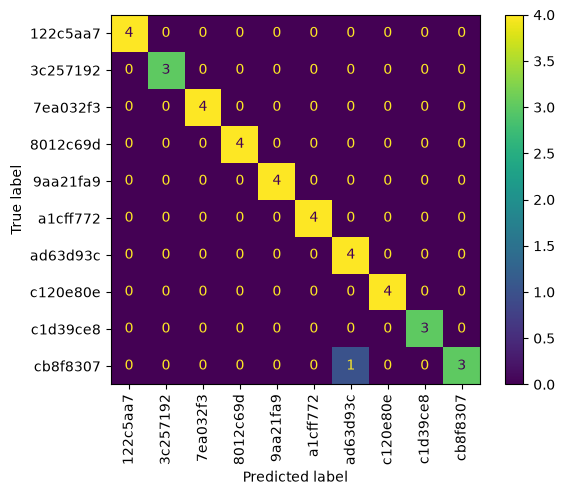

In [10]:
pred_val = model.predict(X_val)
print("akurasi:", accuracy_score(y_val, pred_val))
print("F1 macro:", f1_score(y_val, pred_val, average="macro"))
ConfusionMatrixDisplay.from_predictions(y_val, pred_val, xticks_rotation=90)
plt.show()

## Bonus verifikasi: "dua klip ini orang yang sama?" (kemiripan cosine)
Tiap pasangan klip validasi diberi skor kemiripan. AUC tinggi = pasangan orang sama punya
kemiripan lebih besar dari pasangan orang berbeda.

In [11]:
centered = X_val - X_train.mean(axis=0)        # geser ke tengah supaya cosine lebih adil
val_embeddings = normalize(centered)
similarity = val_embeddings @ val_embeddings.T
val_labels = y_val.to_numpy()
pair_scores = []
pair_same = []
for i in range(len(val_labels)):
    for other in range(i + 1, len(val_labels)):   # tiap pasangan dihitung sekali
        pair_scores.append(similarity[i, other])
        pair_same.append(val_labels[i] == val_labels[other])
print("AUC verifikasi (cosine):", roc_auc_score(pair_same, pair_scores))

AUC verifikasi (cosine): 0.71420418878046


## Langkah 3 — latih ulang di semua data + submission

In [12]:
model.fit(X, y)
predictions = model.predict(X_test)

submission = pd.DataFrame()
submission["id"] = test[ID_COL]
submission["label"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,label
0,1,c120e80e
1,2,c120e80e
2,3,c120e80e
3,4,c120e80e
4,5,c120e80e


## Cek dengan kunci jawaban (HAPUS saat lomba)

In [13]:
test_key = pd.read_csv(TEST_KEY_CSV)
print("F1 macro test (kunci demo):", f1_score(test_key[LABEL_COL], predictions, average="macro"))

F1 macro test (kunci demo): 0.9511655011655012
